In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# WEEK-1

**Data Isolation & Dataset Subsetting**

In [1]:
import os

BASE_PATH = '/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)'
TRAIN_SRC = os.path.join(BASE_PATH, 'train')
VALID_SRC = os.path.join(BASE_PATH, 'valid')
TEST_PATH = '/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test'

# Create working folders for tomato subset
TOMATO_DIR = '/kaggle/working/tomato_dataset'
TRAIN_DIR = os.path.join(TOMATO_DIR, 'train')
VALID_DIR = os.path.join(TOMATO_DIR, 'valid')

def link_tomato_classes(src_dir, dst_dir):
    os.makedirs(dst_dir, exist_ok=True)
    for folder in os.listdir(src_dir):
        if folder.startswith('Tomato___'):
            src_folder = os.path.join(src_dir, folder)
            dst_folder = os.path.join(dst_dir, folder)
            if not os.path.exists(dst_folder):
                os.symlink(src_folder, dst_folder)
                print(f"Linked: {folder}")

link_tomato_classes(TRAIN_SRC, TRAIN_DIR)
link_tomato_classes(VALID_SRC, VALID_DIR)

Linked: Tomato___Late_blight
Linked: Tomato___healthy
Linked: Tomato___Early_blight
Linked: Tomato___Septoria_leaf_spot
Linked: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Linked: Tomato___Bacterial_spot
Linked: Tomato___Target_Spot
Linked: Tomato___Tomato_mosaic_virus
Linked: Tomato___Leaf_Mold
Linked: Tomato___Spider_mites Two-spotted_spider_mite
Linked: Tomato___Late_blight
Linked: Tomato___healthy
Linked: Tomato___Early_blight
Linked: Tomato___Septoria_leaf_spot
Linked: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Linked: Tomato___Bacterial_spot
Linked: Tomato___Target_Spot
Linked: Tomato___Tomato_mosaic_virus
Linked: Tomato___Leaf_Mold
Linked: Tomato___Spider_mites Two-spotted_spider_mite


**Data Loading & Pipeline Optimization**

In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
TOMATO_DIR = '/kaggle/working/tomato_dataset'

train_ds = tf.keras.utils.image_dataset_from_directory(
    f'{TOMATO_DIR}/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    f'{TOMATO_DIR}/valid',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print(f"\nLoaded {NUM_CLASSES} Tomato classes:")
for idx, name in enumerate(class_names):
    print(f"{idx}: {name}")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
valid_ds = valid_ds.prefetch(AUTOTUNE)

Found 18345 files belonging to 10 classes.


I0000 00:00:1788759361.510144      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788759361.512932      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 4585 files belonging to 10 classes.

Loaded 10 Tomato classes:
0: Tomato___Bacterial_spot
1: Tomato___Early_blight
2: Tomato___Late_blight
3: Tomato___Leaf_Mold
4: Tomato___Septoria_leaf_spot
5: Tomato___Spider_mites Two-spotted_spider_mite
6: Tomato___Target_Spot
7: Tomato___Tomato_Yellow_Leaf_Curl_Virus
8: Tomato___Tomato_mosaic_virus
9: Tomato___healthy


**Model Architecture & Two-Stage Transfer Learning**

**MODEL-1:EfficientNetB0**

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
])

#5.3M Parameters
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet', # Pretrained weight learn from 1.4M image
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x) # 7 * 7 * 1280 = 62,720
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = keras.Model(inputs, outputs)

# Stage 1: Feature Extraction
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',  # L = -sum_{i=1}^{C} y_i*log(hat{y}_i) || L = -log(hat{y}_c)
    metrics=['accuracy']
)

callbacks_stage1 = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint('best_tomato_stage1.keras', monitor='val_loss', save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7)
]

print("Starting Stage 1 Training...")
history_stage1 = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=8,
    callbacks=callbacks_stage1
)

# Stage 2: Fine-Tuning
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_stage2 = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint('tomato_efficientnet_finetuned.keras', monitor='val_loss', save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7)
]

print("\nStarting Stage 2 Fine-Tuning...")
history_stage2 = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=8,
    callbacks=callbacks_stage2
)

**Prediction And Result**

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

TEST_PATH = '/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test'
test_files = sorted([f for f in os.listdir(TEST_PATH) if f.startswith('Tomato')])

results = []

plt.figure(figsize=(15, 10))
for i, filename in enumerate(test_files):
    img_path = os.path.join(TEST_PATH, filename)
    raw_img = Image.open(img_path).resize((224, 224))
    
    img_array = tf.keras.utils.img_to_array(raw_img)
    img_batch = tf.expand_dims(img_array, 0)

    preds = model.predict(img_batch, verbose=0)[0]
    pred_idx = np.argmax(preds)
    pred_class = class_names[pred_idx].replace('Tomato___', '')
    confidence = preds[pred_idx]

    results.append({
        'Image': filename,
        'Predicted Disease': pred_class,
        'Confidence': f"{confidence:.2%}"
    })

    if i < 12:
        plt.subplot(3, 4, i + 1)
        plt.imshow(raw_img)
        plt.title(f"{filename}\nPred: {pred_class}\nConf: {confidence:.2%}", fontsize=8)
        plt.axis('off')

plt.tight_layout()
plt.show()

# Display prediction dataframe
results_df = pd.DataFrame(results)
results_df

# WEEK-2

**Global Setup & Dynamic Helper**

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
TOMATO_DIR = '/kaggle/working/tomato_dataset'
TEST_PATH = '/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test'

def get_datasets(img_size):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        f'{TOMATO_DIR}/train',
        image_size=img_size,
        batch_size=BATCH_SIZE,
        shuffle=True,
        seed=42
    )
    valid_ds = tf.keras.utils.image_dataset_from_directory(
        f'{TOMATO_DIR}/valid',
        image_size=img_size,
        batch_size=BATCH_SIZE,
        shuffle=False
    )
    class_names = train_ds.class_names
    return train_ds.prefetch(AUTOTUNE), valid_ds.prefetch(AUTOTUNE), class_names

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")

def save_learning_curves(h1, h2, model_name):
    acc = h1.history['accuracy'] + h2.history['accuracy']
    val_acc = h1.history['val_accuracy'] + h2.history['val_accuracy']
    loss = h1.history['loss'] + h2.history['loss']
    val_loss = h1.history['val_loss'] + h2.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
    plt.axvline(x=len(h1.history['accuracy']), color='gray', linestyle='--', label='Fine-Tuning Start')
    plt.title(f'{model_name} - Accuracy Curve')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss', marker='o')
    plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
    plt.axvline(x=len(h1.history['loss']), color='gray', linestyle='--', label='Fine-Tuning Start')
    plt.title(f'{model_name} - Loss Curve')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True)

    plt.tight_layout()
    file_path = f'{model_name}_learning_curves.png'
    plt.savefig(file_path, dpi=300)
    plt.show()

def save_prediction_grid(model, model_name, target_size, class_names):
    test_files = sorted([f for f in os.listdir(TEST_PATH) if f.startswith('Tomato')])
    plt.figure(figsize=(16, 12))
    plt.suptitle(f'Test Set Predictions - {model_name}', fontsize=16, fontweight='bold')

    for i, filename in enumerate(test_files[:12]):
        img_path = os.path.join(TEST_PATH, filename)
        raw_img = Image.open(img_path).resize(target_size)
        img_array = tf.keras.utils.img_to_array(raw_img)
        img_batch = tf.expand_dims(img_array, 0)

        preds = model.predict(img_batch, verbose=0)[0]
        pred_idx = np.argmax(preds)
        pred_class = class_names[pred_idx].replace('Tomato___', '')
        confidence = preds[pred_idx]

        plt.subplot(3, 4, i + 1)
        plt.imshow(raw_img)
        plt.title(f"{filename}\nPred: {pred_class}\nConf: {confidence:.2%}", fontsize=9)
        plt.axis('off')

    plt.tight_layout()
    file_path = f'{model_name}_test_predictions.png'
    plt.savefig(file_path, dpi=300)
    plt.show()

summary_report_data = {}

**Model-2: MobileNetV2**

Found 18345 files belonging to 10 classes.
Found 4585 files belonging to 10 classes.
Epoch 1/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 45s 71ms/step - accuracy: 0.7068 - loss: 0.8708 - val_accuracy: 0.7974 - val_loss: 0.6024
Epoch 2/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 40s 70ms/step - accuracy: 0.8212 - loss: 0.5346 - val_accuracy: 0.8246 - val_loss: 0.5231
Epoch 3/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 39s 68ms/step - accuracy: 0.8404 - loss: 0.4720 - val_accuracy: 0.8109 - val_loss: 0.5549
Epoch 4/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 40s 70ms/step - accuracy: 0.8501 - loss: 0.4471 - val_accuracy: 0.8532 - val_loss: 0.4512
Epoch 5/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 40s 69ms/step - accuracy: 0.8573 - loss: 0.4155 - val_accuracy: 0.8561 - val_loss: 0.4310
Epoch 6/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 40s 69ms/step - accuracy: 0.8633 - loss: 0.3989 - val_accuracy: 0.8615 - val_loss: 0.4092
Epoch 7/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 40s 69ms/step - accuracy: 0.8660 - loss: 0.3952 - val_accuracy: 0.8632 - val_loss: 0.4039
Epoch 8/8
57

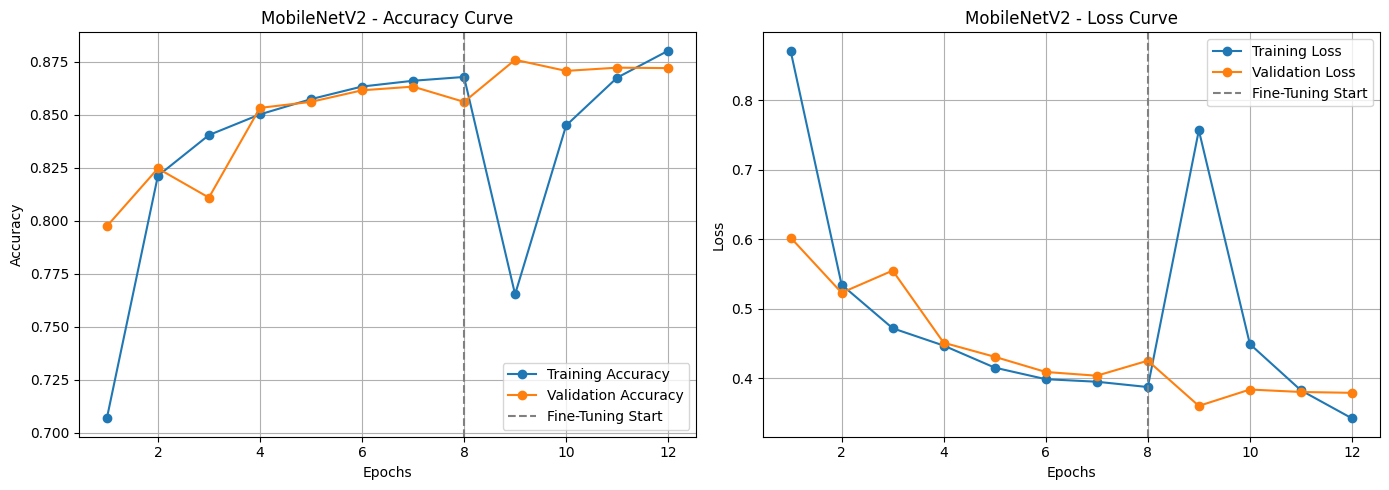

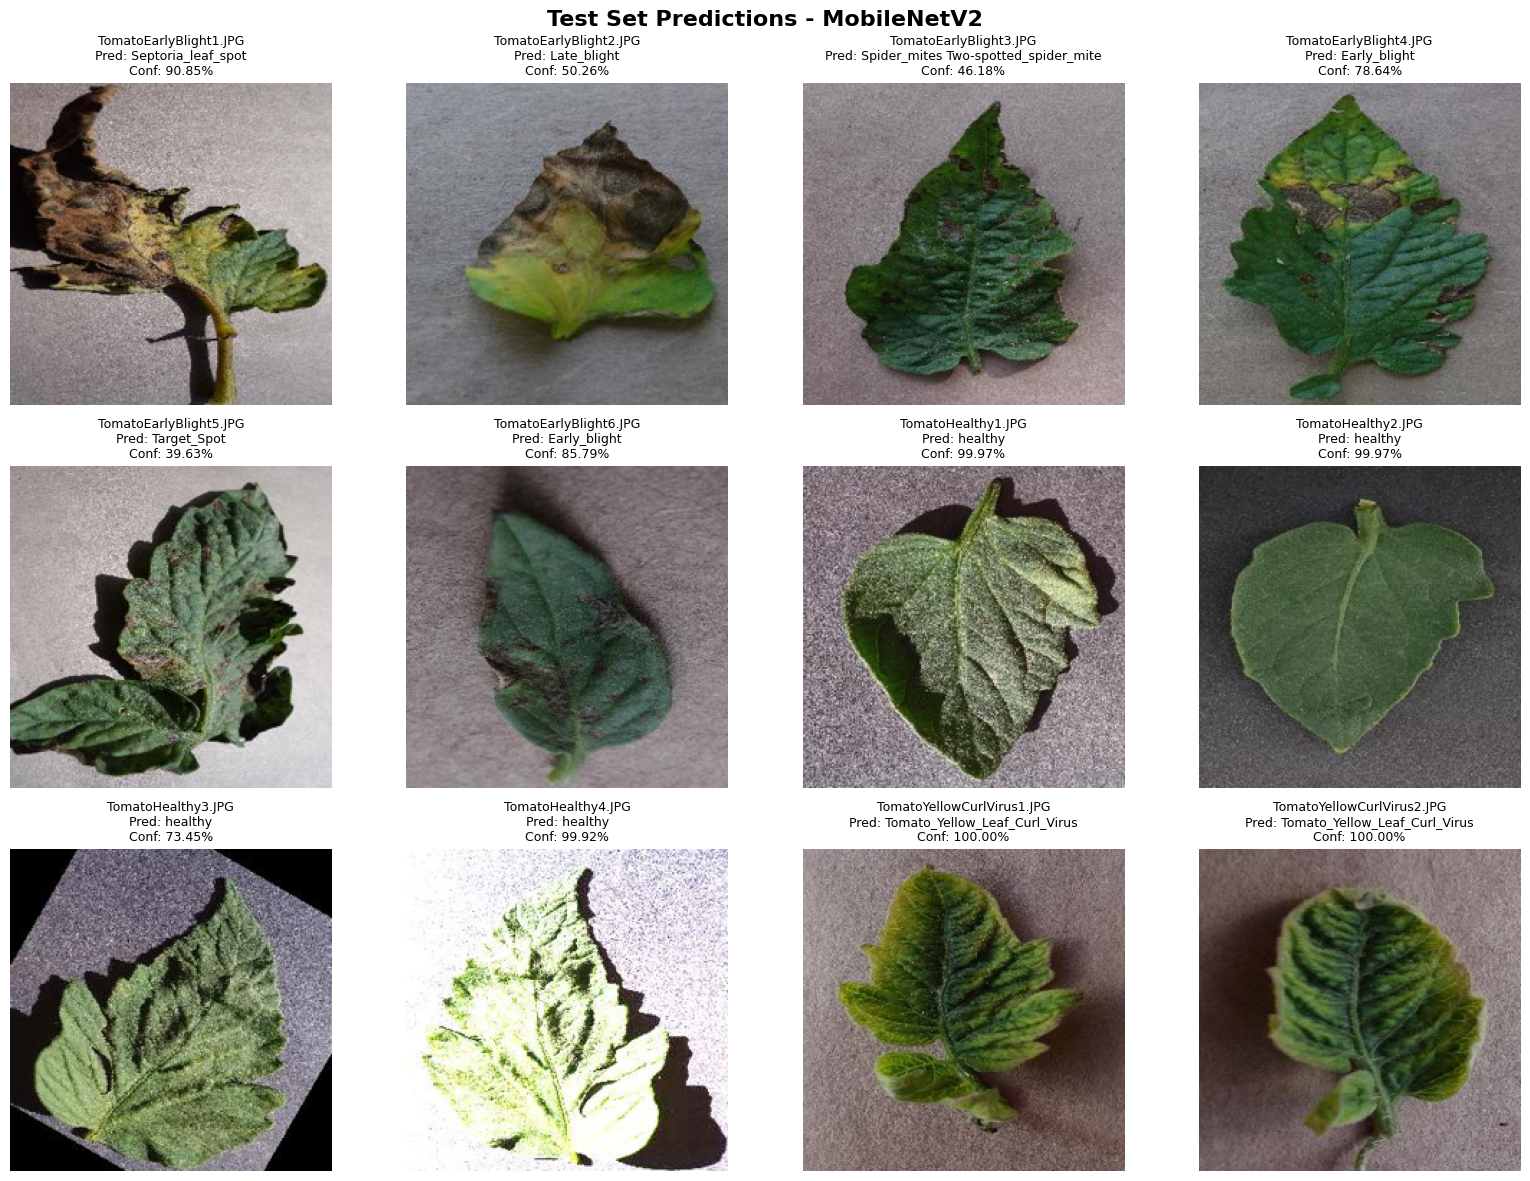

In [8]:
MODEL_NAME = 'MobileNetV2'
IMG_SIZE = (224, 224)
INPUT_SHAPE = (224, 224, 3)

train_ds_mnet, valid_ds_mnet, class_names = get_datasets(IMG_SIZE)

inputs = keras.Input(shape=INPUT_SHAPE)
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

base_mnet = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=INPUT_SHAPE)
base_mnet.trainable = False

x = base_mnet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)

model_mnet = keras.Model(inputs, outputs)

model_mnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_s1 = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f'best_{MODEL_NAME}_stage1.keras', monitor='val_loss', save_best_only=True)
]

h1_mnet = model_mnet.fit(train_ds_mnet, validation_data=valid_ds_mnet, epochs=8, callbacks=callbacks_s1)

base_mnet.trainable = True
for layer in base_mnet.layers[:-20]:
    layer.trainable = False

model_mnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
#Fine Tunning
callbacks_s2 = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f'best_{MODEL_NAME}_finetuned.keras', monitor='val_loss', save_best_only=True)
]

h2_mnet = model_mnet.fit(train_ds_mnet, validation_data=valid_ds_mnet, epochs=8, callbacks=callbacks_s2)

save_learning_curves(h1_mnet, h2_mnet, MODEL_NAME)
save_prediction_grid(model_mnet, MODEL_NAME, IMG_SIZE, class_names)

summary_report_data[MODEL_NAME] = {
    'Resolution': '224x224',
    'Parameters': f"{model_mnet.count_params():,}",
    'Stage 1 Val Acc': f"{max(h1_mnet.history['val_accuracy']):.2%}",
    'Stage 2 Val Acc': f"{max(h2_mnet.history['val_accuracy']):.2%}",
    'Final Val Loss': f"{min(h2_mnet.history['val_loss']):.4f}"
}

**Model-3: DenseNet121**

Found 18345 files belonging to 10 classes.
Found 4585 files belonging to 10 classes.
Epoch 1/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 123s 193ms/step - accuracy: 0.6483 - loss: 1.0879 - val_accuracy: 0.7974 - val_loss: 0.6413
Epoch 2/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 108s 188ms/step - accuracy: 0.8108 - loss: 0.6043 - val_accuracy: 0.8430 - val_loss: 0.4857
Epoch 3/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 107s 187ms/step - accuracy: 0.8348 - loss: 0.5119 - val_accuracy: 0.8600 - val_loss: 0.4397
Epoch 4/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 106s 185ms/step - accuracy: 0.8461 - loss: 0.4743 - val_accuracy: 0.8523 - val_loss: 0.4475
Epoch 5/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 107s 187ms/step - accuracy: 0.8520 - loss: 0.4461 - val_accuracy: 0.8678 - val_loss: 0.3964
Epoch 6/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 106s 184ms/step - accuracy: 0.8568 - loss: 0.4253 - val_accuracy: 0.8654 - val_loss: 0.3969
Epoch 7/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 106s 184ms/step - accuracy: 0.8594 - loss: 0.4149 - val_accuracy: 0.8506 - val_loss: 0.436

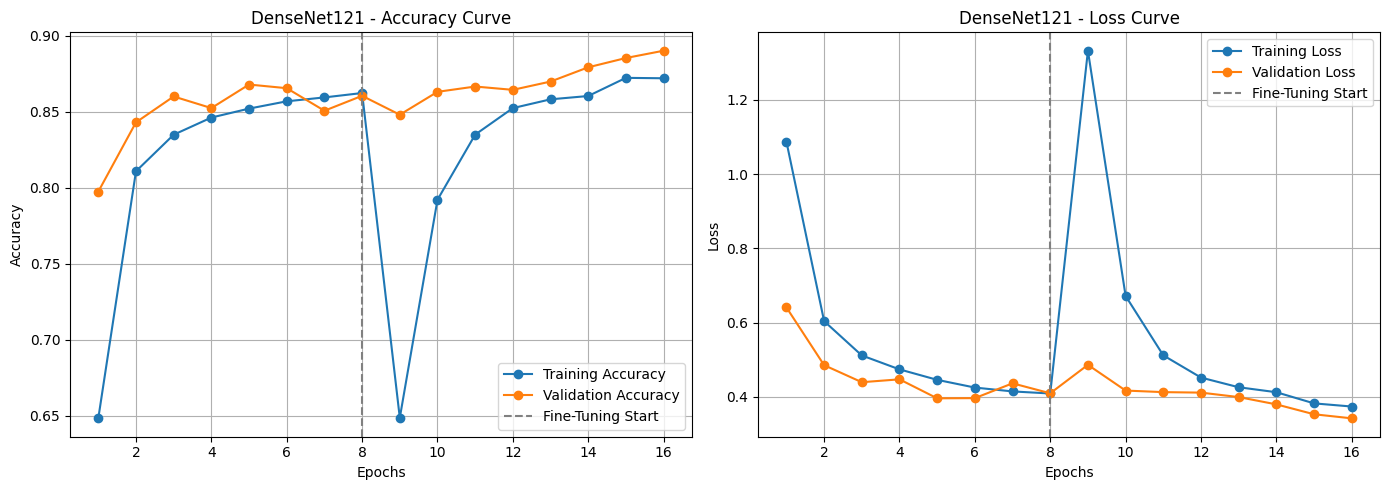

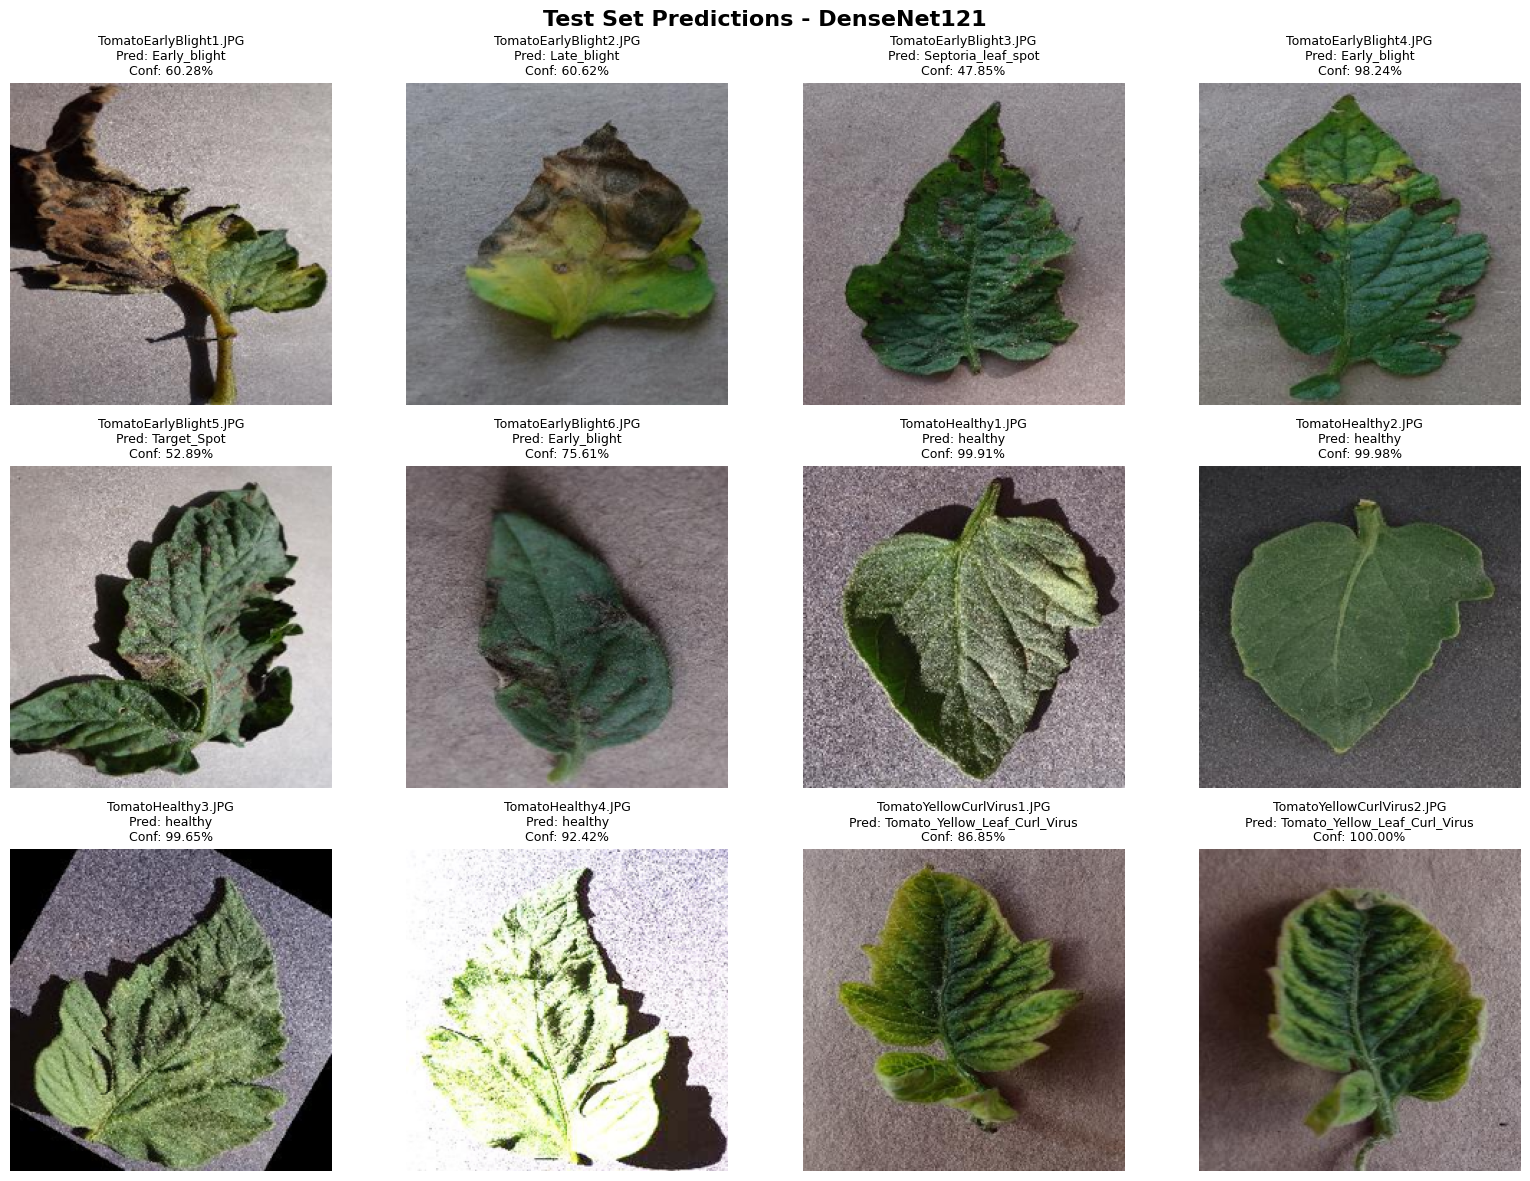

In [9]:
MODEL_NAME = 'DenseNet121'
IMG_SIZE = (224, 224)
INPUT_SHAPE = (224, 224, 3)

train_ds_dnet, valid_ds_dnet, class_names = get_datasets(IMG_SIZE)

inputs = keras.Input(shape=INPUT_SHAPE)
x = data_augmentation(inputs)
x = tf.keras.applications.densenet.preprocess_input(x)

base_dnet = tf.keras.applications.DenseNet121(include_top=False, weights='imagenet', input_shape=INPUT_SHAPE)
base_dnet.trainable = False

x = base_dnet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)

model_dnet = keras.Model(inputs, outputs)

model_dnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_s1 = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f'best_{MODEL_NAME}_stage1.keras', monitor='val_loss', save_best_only=True)
]

h1_dnet = model_dnet.fit(train_ds_dnet, validation_data=valid_ds_dnet, epochs=8, callbacks=callbacks_s1)

base_dnet.trainable = True
for layer in base_dnet.layers[:-20]:
    layer.trainable = False

model_dnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
#Fine Tunning
callbacks_s2 = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f'best_{MODEL_NAME}_finetuned.keras', monitor='val_loss', save_best_only=True)
]

h2_dnet = model_dnet.fit(train_ds_dnet, validation_data=valid_ds_dnet, epochs=8, callbacks=callbacks_s2)

save_learning_curves(h1_dnet, h2_dnet, MODEL_NAME)
save_prediction_grid(model_dnet, MODEL_NAME, IMG_SIZE, class_names)

summary_report_data[MODEL_NAME] = {
    'Resolution': '224x224',
    'Parameters': f"{model_dnet.count_params():,}",
    'Stage 1 Val Acc': f"{max(h1_dnet.history['val_accuracy']):.2%}",
    'Stage 2 Val Acc': f"{max(h2_dnet.history['val_accuracy']):.2%}",
    'Final Val Loss': f"{min(h2_dnet.history['val_loss']):.4f}"
}

**Model-4: EfficientNetB3**

Found 18345 files belonging to 10 classes.
Found 4585 files belonging to 10 classes.
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
[EfficientNetB3] Starting Stage 1 Feature Extraction...
Epoch 1/8


E0000 00:00:1788765196.430161      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_7_1/efficientnetb3_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


574/574 ━━━━━━━━━━━━━━━━━━━━ 208s 334ms/step - accuracy: 0.7227 - loss: 0.9220 - val_accuracy: 0.7913 - val_loss: 0.6602
Epoch 2/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 185s 321ms/step - accuracy: 0.8391 - loss: 0.5204 - val_accuracy: 0.8530 - val_loss: 0.4754
Epoch 3/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 184s 321ms/step - accuracy: 0.8696 - loss: 0.4279 - val_accuracy: 0.8602 - val_loss: 0.4274
Epoch 4/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 184s 321ms/step - accuracy: 0.8759 - loss: 0.3888 - val_accuracy: 0.8750 - val_loss: 0.3891
Epoch 5/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 184s 321ms/step - accuracy: 0.8906 - loss: 0.3521 - val_accuracy: 0.8912 - val_loss: 0.3396
Epoch 6/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 184s 321ms/step - accuracy: 0.8952 - loss: 0.3315 - val_accuracy: 0.8966 - val_loss: 0.3191
Epoch 7/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 185s 322ms/step - accuracy: 0.8963 - loss: 0.3169 - val_accuracy: 0.8997 - val_loss: 0.3124
Epoch 8/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 190s 331ms/step - accuracy: 0.9012 - loss: 0.3033 - va

E0000 00:00:1788766702.782252      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_7_1/efficientnetb3_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


574/574 ━━━━━━━━━━━━━━━━━━━━ 225s 362ms/step - accuracy: 0.8742 - loss: 0.3772 - val_accuracy: 0.9101 - val_loss: 0.2796
Epoch 2/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 203s 354ms/step - accuracy: 0.9015 - loss: 0.2885 - val_accuracy: 0.9208 - val_loss: 0.2423
Epoch 3/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 203s 354ms/step - accuracy: 0.9174 - loss: 0.2487 - val_accuracy: 0.9365 - val_loss: 0.2037
Epoch 4/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 203s 354ms/step - accuracy: 0.9279 - loss: 0.2226 - val_accuracy: 0.9411 - val_loss: 0.1875
Epoch 5/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 203s 355ms/step - accuracy: 0.9345 - loss: 0.1975 - val_accuracy: 0.9457 - val_loss: 0.1724
Epoch 6/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 203s 354ms/step - accuracy: 0.9369 - loss: 0.1889 - val_accuracy: 0.9527 - val_loss: 0.1541
Epoch 7/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 204s 355ms/step - accuracy: 0.9442 - loss: 0.1696 - val_accuracy: 0.9581 - val_loss: 0.1389
Epoch 8/8
574/574 ━━━━━━━━━━━━━━━━━━━━ 203s 354ms/step - accuracy: 0.9475 - loss: 0.1607 - va

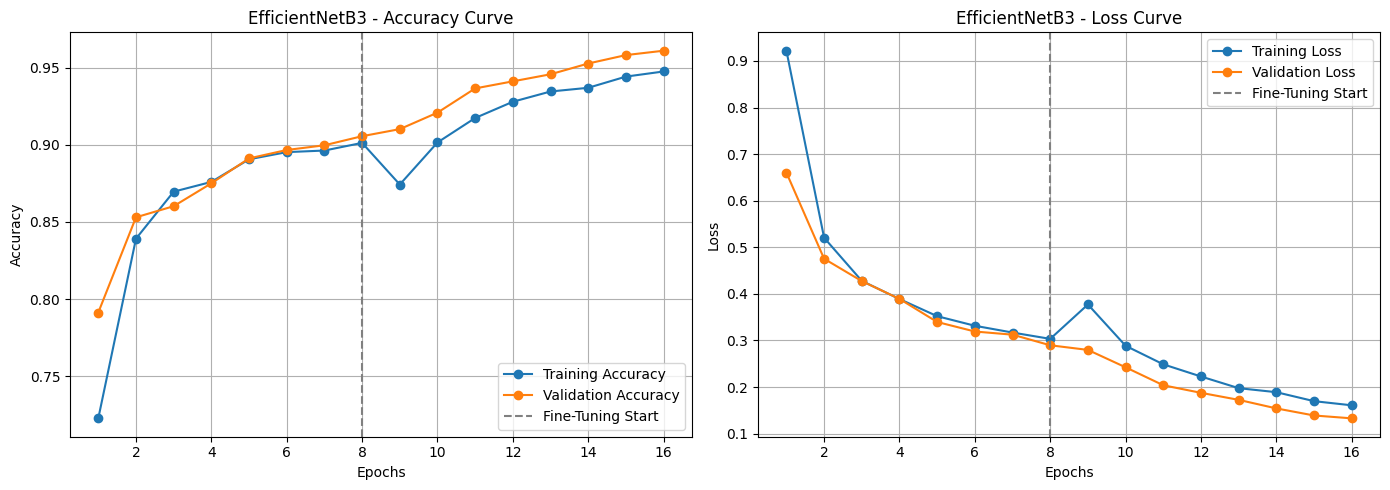

Saved learning curve image: EfficientNetB3_learning_curves.png


In [12]:
MODEL_NAME = 'EfficientNetB3'
IMG_SIZE = (300, 300)
INPUT_SHAPE = (300, 300, 3)

# 1. Load Raw Datasets for 300x300 Resolution
train_raw = tf.keras.utils.image_dataset_from_directory(
    f'{TOMATO_DIR}/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)
valid_raw = tf.keras.utils.image_dataset_from_directory(
    f'{TOMATO_DIR}/valid',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_raw.class_names
train_ds_b3 = train_raw.prefetch(AUTOTUNE)
valid_ds_b3 = valid_raw.prefetch(AUTOTUNE)

# 2. Local Augmentation Pipeline (Independent of 224x224 models)
data_aug_b3 = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
], name="aug_b3")

# 3. Model Architecture
inputs = keras.Input(shape=INPUT_SHAPE)
x = data_aug_b3(inputs)

base_b3 = tf.keras.applications.EfficientNetB3(
    include_top=False, weights='imagenet', input_shape=INPUT_SHAPE
)
base_b3.trainable = False

x = base_b3(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)

model_b3 = keras.Model(inputs, outputs)

# 4. Stage 1: Feature Extraction
model_b3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_s1 = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f'best_{MODEL_NAME}_stage1.keras', monitor='val_loss', save_best_only=True)
]

print(f"[{MODEL_NAME}] Starting Stage 1 Feature Extraction...")
h1_b3 = model_b3.fit(train_ds_b3, validation_data=valid_ds_b3, epochs=8, callbacks=callbacks_s1)

# 5. Stage 2: Fine-Tuning Top Layers
base_b3.trainable = True
for layer in base_b3.layers[:-20]:
    layer.trainable = False

model_b3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_s2 = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f'best_{MODEL_NAME}_finetuned.keras', monitor='val_loss', save_best_only=True)
]

print(f"\n[{MODEL_NAME}] Starting Stage 2 Fine-Tuning...")
h2_b3 = model_b3.fit(train_ds_b3, validation_data=valid_ds_b3, epochs=8, callbacks=callbacks_s2)

# 6. Save EfficientNetB3 Learning Curve Diagram Image
acc = h1_b3.history['accuracy'] + h2_b3.history['accuracy']
val_acc = h1_b3.history['val_accuracy'] + h2_b3.history['val_accuracy']
loss = h1_b3.history['loss'] + h2_b3.history['loss']
val_loss = h1_b3.history['val_loss'] + h2_b3.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.axvline(x=len(h1_b3.history['accuracy']), color='gray', linestyle='--', label='Fine-Tuning Start')
plt.title(f'{MODEL_NAME} - Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.axvline(x=len(h1_b3.history['loss']), color='gray', linestyle='--', label='Fine-Tuning Start')
plt.title(f'{MODEL_NAME} - Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
b3_curve_path = f'{MODEL_NAME}_learning_curves.png'
plt.savefig(b3_curve_path, dpi=300)
plt.show()
print(f"Saved learning curve image: {b3_curve_path}")

Found 18345 files belonging to 10 classes.


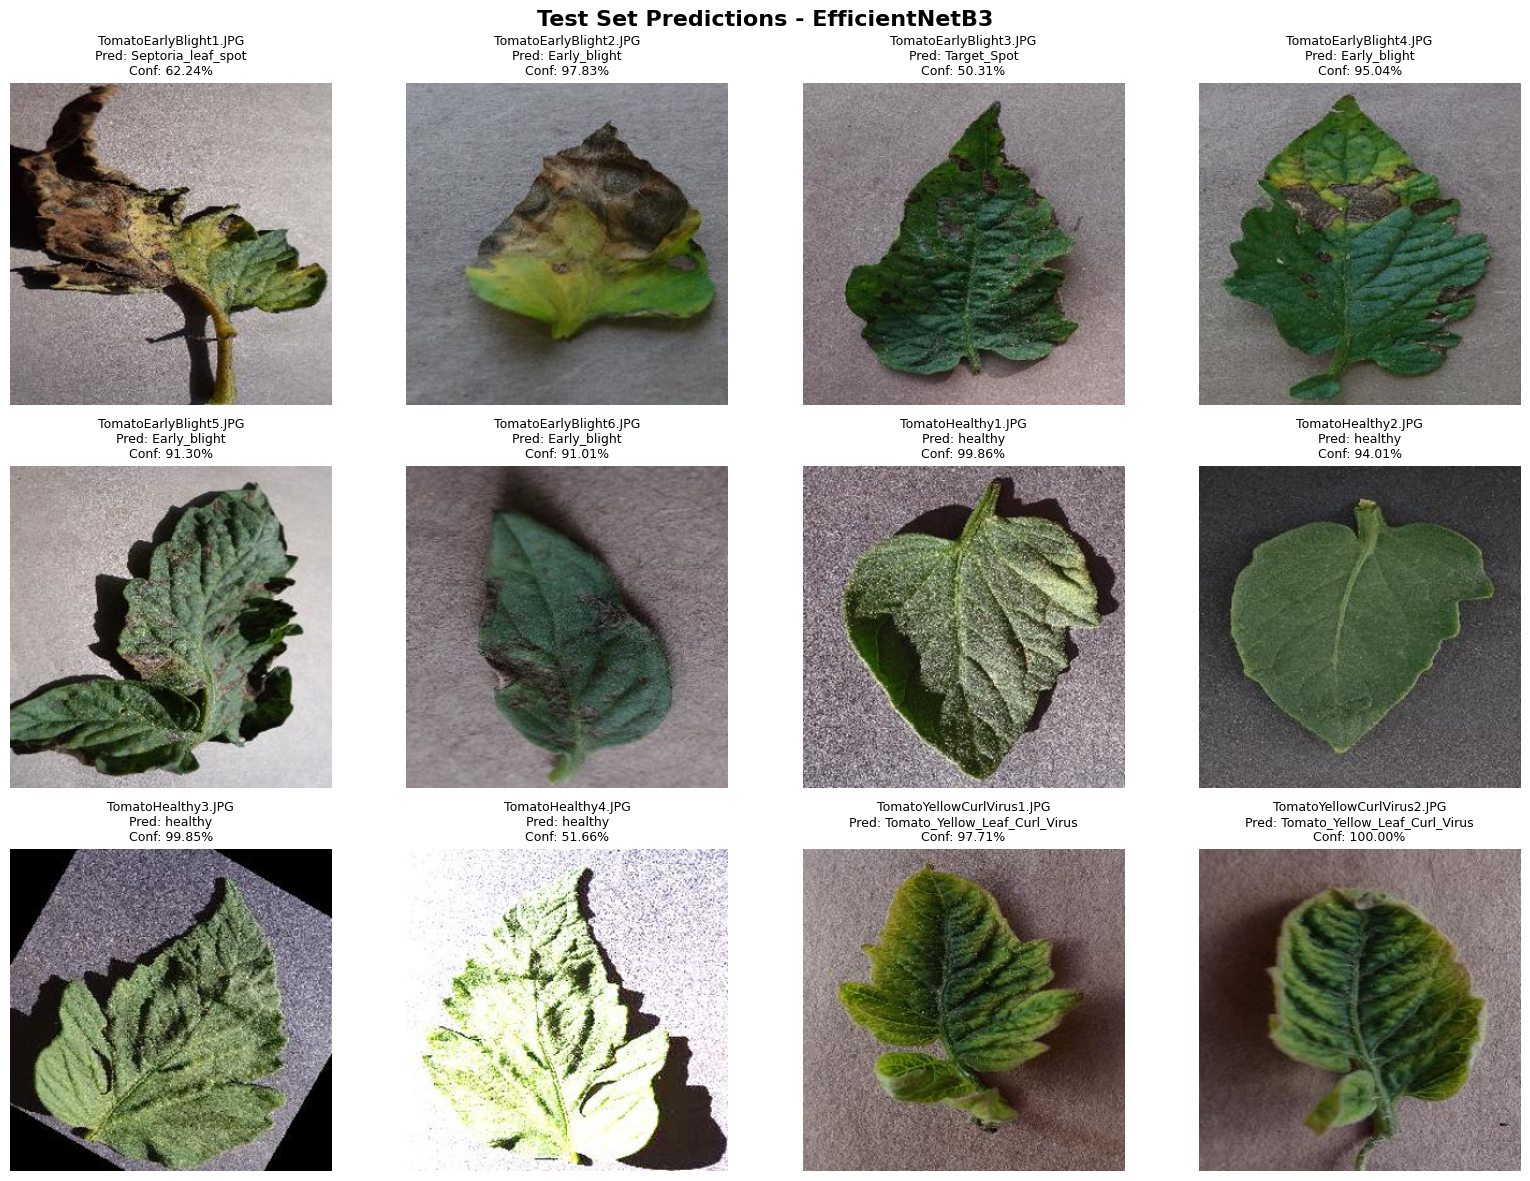

Saved prediction image: EfficientNetB3_test_predictions.png


In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

TEST_PATH = '/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test'
TOMATO_DIR = '/kaggle/working/tomato_dataset'

# Load dataset class labels
train_raw = tf.keras.utils.image_dataset_from_directory(
    f'{TOMATO_DIR}/train',
    image_size=(300, 300),
    batch_size=32,
    shuffle=False
)
class_names = train_raw.class_names

# Load saved EfficientNetB3 weights
model_b3 = tf.keras.models.load_model('best_EfficientNetB3_finetuned.keras')

# Get test set tomato images
test_files = sorted([f for f in os.listdir(TEST_PATH) if f.startswith('Tomato')])

# Render prediction grid
plt.figure(figsize=(16, 12))
plt.suptitle('Test Set Predictions - EfficientNetB3', fontsize=16, fontweight='bold')

for i, filename in enumerate(test_files[:12]):
    img_path = os.path.join(TEST_PATH, filename)
    raw_img = Image.open(img_path).resize((300, 300))
    img_array = tf.keras.utils.img_to_array(raw_img)
    img_batch = tf.expand_dims(img_array, 0)

    preds = model_b3.predict(img_batch, verbose=0)[0]
    pred_idx = np.argmax(preds)
    pred_class = class_names[pred_idx].replace('Tomato___', '')
    confidence = preds[pred_idx]

    plt.subplot(3, 4, i + 1)
    plt.imshow(raw_img)
    plt.title(f"{filename}\nPred: {pred_class}\nConf: {confidence:.2%}", fontsize=9)
    plt.axis('off')

plt.tight_layout()
b3_pred_path = 'EfficientNetB3_test_predictions.png'
plt.savefig(b3_pred_path, dpi=300)
plt.show()

print(f"Saved prediction image: {b3_pred_path}")